# Assignment 1 – Parkinson's Disease Classification
**Name:** Davisen Veerasamy  
**Course:** CSCN8000 Artificial Intelligence Algorithms and Mathematics  

**Goal:** Use voice (speech) measurements from patients to predict whether a person is likely to have Parkinson's disease.
A model like this could help doctors as a decision support tool.

**Dataset:** [UCI – Parkinson's Disease Classification](https://archive.ics.uci.edu/dataset/470/parkinson+s+disease+classification)

## Setup and Configuration
This section has everything needed to run the rest of the notebook:
1. Install the required libraries
2. Import the libraries
3. Set the settings used in the notebook (data file path, test size and random state)
4. Check the library versions

**Note:** Open and run this notebook from the main project folder (`CSCN8000-Assignment1`),
because the data file is read from the `data` folder inside it.

### 1. Install the required libraries
This only needs to be run once. If the libraries are already installed, it will just say so.

In [ ]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn

### 2. Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

### 3. Settings
These values are used later in the notebook. Keeping them in one place makes them easy to find and change.
- `DATA_PATH`: where the dataset is saved
- `TEST_SIZE`: 0.2 means 20% of the data is used for testing and 80% for training (Question 2)
- `RANDOM_STATE`: a fixed number so the split and the models give the same results every time
- `OUTPUT_FILE`: the name of the CSV file for the test predictions (Question 7)

In [2]:
DATA_PATH = "data/pd_speech_features.csv"
TEST_SIZE = 0.2
RANDOM_STATE = 42
OUTPUT_FILE = "predictions/test_predictions.csv"

### 4. Check the library versions
The results in this notebook were made with these versions. Different versions might give slightly different numbers.

In [3]:
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", plt.matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 3.1.1
numpy: 2.5.5
matplotlib: 3.11.2
seaborn: 0.13.2
scikit-learn: 1.9.1


## Question 1: Data preprocessing (if required) steps to complete:
i. Data Analysis  
ii. Data Preprocessing  
iii. Data Standardization

### i. Data Analysis
The first row of the CSV file only has group names (like "Baseline Features" and "MFCC"),
so the real column names are on the second row. That is why `header=1` is used.

In [4]:
df = pd.read_csv(DATA_PATH, header=1)
df.head()

,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


In [5]:
# Number of rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 756
Columns: 755


In [6]:
# Data types of the columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Columns: 755 entries, id to class
dtypes: float64(749), int64(6)
memory usage: 4.4 MB


In [7]:
# Check for missing values
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [8]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1


In [9]:
# Each patient (id) has more than one voice recording
print("Number of unique patients:", df["id"].nunique())
print("Recordings per patient:", df["id"].value_counts().unique())

Number of unique patients: 252
Recordings per patient: [3]


class
1    564
0    192
Name: count, dtype: int64


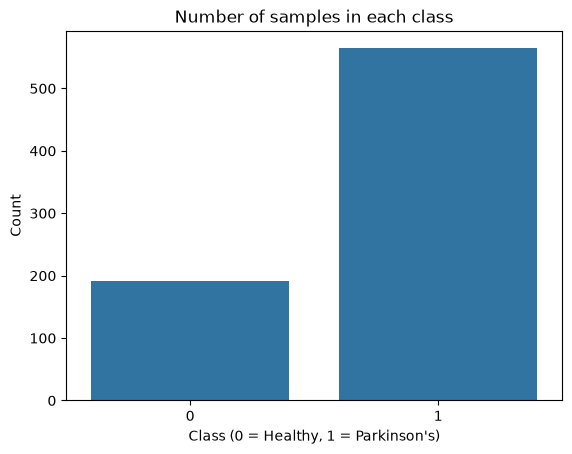

In [10]:
# How many samples are in each class (1 = Parkinson's, 0 = Healthy)
print(df["class"].value_counts())

sns.countplot(x="class", data=df)
plt.title("Number of samples in each class")
plt.xlabel("Class (0 = Healthy, 1 = Parkinson's)")
plt.ylabel("Count")
plt.show()

In [11]:
# Gender count (0 = female, 1 = male)
print(df["gender"].value_counts())

gender
1    390
0    366
Name: count, dtype: int64


In [12]:
# Basic statistics for the first few feature columns
df.iloc[:, 1:10].describe()

,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter
count,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000
mean,0.515873,0.746284,0.700414,0.489058,323.972222,322.678571,0.006360,0.000383,0.002324
std,0.500079,0.169294,0.069718,0.137442,99.219059,99.402499,0.001826,0.000728,0.002628
min,0.000000,0.041551,0.543500,0.154300,2.000000,1.000000,0.002107,0.000011,0.000210
25%,0.000000,0.762833,0.647053,0.386537,251.000000,250.000000,0.005003,0.000049,0.000970
50%,1.000000,0.809655,0.700525,0.484355,317.000000,316.000000,0.006048,0.000077,0.001495
75%,1.000000,0.834315,0.754985,0.586515,384.250000,383.250000,0.007528,0.000171,0.002520
max,1.000000,0.907660,0.852640,0.871230,907.000000,905.000000,0.012966,0.003483,0.027750


**What I found from the data analysis:**
- The dataset has 756 rows (voice recordings) and 755 columns (753 features, plus `id` and `class`).
- There are 252 patients, and each patient has 3 recordings.
- There are no missing values, but there is 1 duplicate row (the same recording appears twice).
- All columns are numbers, so no text needs to be converted.
- The classes are not balanced: there are many more Parkinson's samples (564) than healthy samples (192).
- The features have very different ranges (for example some values are less than 1 and others are in the thousands), so standardization will be needed.

### ii. Data Preprocessing
- The `id` column is only a patient number. It does not help predict the disease, so it is removed.
- There are no missing values, so nothing needs to be filled in.
- The 1 duplicate row is removed so the same recording is not counted twice.
- The data is split into features (`X`) and the target (`y`). The target is the `class` column.

In [13]:
# Remove the duplicate row
df = df.drop_duplicates()
print("Rows after removing duplicates:", df.shape[0])

# Remove the id column
df = df.drop(columns=["id"])

# Features (X) and target (y)
X = df.drop(columns=["class"])
y = df["class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

Rows after removing duplicates: 755
X shape: (755, 753)
y shape: (755,)


### iii. Data Standardization
Standardization changes every feature so it has a mean of 0 and a standard deviation of 1.
This is important for KNN and SVM because they use distances, and features with big numbers would
otherwise have too much effect.

I create the `StandardScaler` here. It is fitted **only on the training data** after the split in Question 2,
and then used to transform the test data. This way the model does not "see" the test data during training.

In [14]:
scaler = StandardScaler()

## Question 2: Use 80% of samples as training data size.
`TEST_SIZE` (0.2) means 20% is used for testing and 80% for training.
`stratify=y` keeps the same ratio of Parkinson's and healthy samples in both sets.
`RANDOM_STATE` (42) makes the results the same every time the notebook is run.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 604
Testing samples: 151


In [16]:
# Standardize the data (fit on training data only)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Mean of training data after scaling (approx):", round(X_train_scaled.mean(), 4))
print("Std of training data after scaling (approx):", round(X_train_scaled.std(), 4))

Mean of training data after scaling (approx): 0.0
Std of training data after scaling (approx): 1.0


## Question 3: Model Training: Use the following models to train the data:
i. K-Nearest Neighbors (KNN)  
ii. Random Forest  
iii. Support Vector Machine (SVM)  
iv. Decision Tree

All four models are trained on the same scaled training data. Default settings are used to keep it simple.

In [17]:
# i. K-Nearest Neighbors
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# ii. Random Forest
rf_model = RandomForestClassifier(random_state=RANDOM_STATE)
rf_model.fit(X_train_scaled, y_train)

# iii. Support Vector Machine
svm_model = SVC(random_state=RANDOM_STATE)
svm_model.fit(X_train_scaled, y_train)

# iv. Decision Tree
dt_model = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_model.fit(X_train_scaled, y_train)

print("All models are trained.")

All models are trained.


## Question 4: Predict the class (patient's Parkinson's disease) on the test data for all the models.

In [18]:
knn_pred = knn_model.predict(X_test_scaled)
rf_pred = rf_model.predict(X_test_scaled)
svm_pred = svm_model.predict(X_test_scaled)
dt_pred = dt_model.predict(X_test_scaled)

# Show the first 10 predictions next to the actual values
first_10 = pd.DataFrame({
    "Actual": y_test.values[:10],
    "KNN": knn_pred[:10],
    "Random Forest": rf_pred[:10],
    "SVM": svm_pred[:10],
    "Decision Tree": dt_pred[:10],
})
first_10

,Actual,KNN,Random Forest,SVM,Decision Tree
0,1,0,1,1,1
1,1,1,1,1,1
2,0,0,0,0,0
3,1,1,1,1,1
4,0,0,0,0,0
5,0,0,0,0,1
6,1,1,1,1,0
7,1,1,1,1,1
8,1,1,1,1,1
9,0,1,0,0,0


## Question 5: Build a predictive system to verify that the models built can predict the patient's Parkinson's disease with a new sample.
The predictive system takes the voice measurements of one patient, scales them with the same scaler,
and asks each model for a prediction.  
To test it, I take one sample from the test data (the models did not train on it) and compare the prediction with the real answer.

In [19]:
def predict_parkinsons(input_data):
    # Change the input to a numpy array and reshape it to one row
    input_array = np.asarray(input_data).reshape(1, -1)

    # Scale it with the same scaler used for training
    input_df = pd.DataFrame(input_array, columns=X.columns)
    input_scaled = scaler.transform(input_df)

    models = {
        "KNN": knn_model,
        "Random Forest": rf_model,
        "SVM": svm_model,
        "Decision Tree": dt_model,
    }

    for name, model in models.items():
        prediction = model.predict(input_scaled)[0]
        if prediction == 1:
            print(name, "-> The person HAS Parkinson's disease")
        else:
            print(name, "-> The person does NOT have Parkinson's disease")

In [20]:
# Test with a Parkinson's sample (row 1 of the test data)
new_sample = X_test.iloc[1].values
print("Actual class:", y_test.iloc[1], "(1 = Parkinson's, 0 = Healthy)")
print()
predict_parkinsons(new_sample)

Actual class: 1 (1 = Parkinson's, 0 = Healthy)

KNN -> The person HAS Parkinson's disease
Random Forest -> The person HAS Parkinson's disease
SVM -> The person HAS Parkinson's disease
Decision Tree -> The person HAS Parkinson's disease


In [21]:
# Test with a healthy sample from the test data
# (row 2 of the test data is a healthy person, as seen in the Question 4 table)
healthy_index = 2
new_sample = X_test.iloc[healthy_index].values
print("Actual class:", y_test.iloc[healthy_index], "(1 = Parkinson's, 0 = Healthy)")
print()
predict_parkinsons(new_sample)

Actual class: 0 (1 = Parkinson's, 0 = Healthy)

KNN -> The person does NOT have Parkinson's disease
Random Forest -> The person does NOT have Parkinson's disease
SVM -> The person does NOT have Parkinson's disease
Decision Tree -> The person does NOT have Parkinson's disease


In both tests, all four models gave the correct answer, so the predictive system works.
However, the models are not always right. In the Question 4 table, KNN got row 0 wrong,
the Decision Tree got rows 5 and 6 wrong, and KNN predicted Parkinson's for a healthy person in row 9. This is looked at more closely in Question 6.

## Question 6: Measure models accuracies and find the best model (highest accuracy). Also, find confusion matrix and classification report for all the models. Summarize the final outputs of these evaluation matrices.

### Accuracy of each model

In [22]:
predictions = {
    "KNN": knn_pred,
    "Random Forest": rf_pred,
    "SVM": svm_pred,
    "Decision Tree": dt_pred,
}

accuracies = {}
for name, pred in predictions.items():
    accuracies[name] = accuracy_score(y_test, pred)

accuracy_table = pd.DataFrame(list(accuracies.items()), columns=["Model", "Accuracy"])
accuracy_table = accuracy_table.sort_values(by="Accuracy", ascending=False)
accuracy_table

,Model,Accuracy
1,Random Forest,0.867550
2,SVM,0.841060
0,KNN,0.834437
3,Decision Tree,0.814570


In [23]:
best_model = max(accuracies, key=accuracies.get)
print("Best model:", best_model)
print("Accuracy:", round(accuracies[best_model] * 100, 2), "%")

Best model: Random Forest
Accuracy: 86.75 %


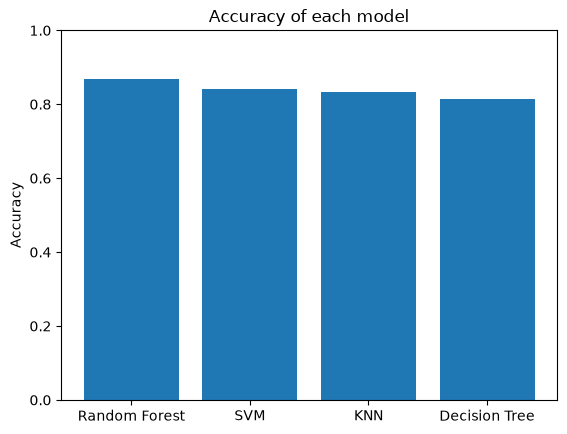

In [24]:
plt.bar(accuracy_table["Model"], accuracy_table["Accuracy"])
plt.title("Accuracy of each model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

### Confusion matrix for each model
In each matrix the rows are the actual class and the columns are the predicted class.
- Top-left: healthy people correctly predicted as healthy
- Top-right: healthy people wrongly predicted as Parkinson's (false positive)
- Bottom-left: Parkinson's patients wrongly predicted as healthy (false negative)
- Bottom-right: Parkinson's patients correctly predicted

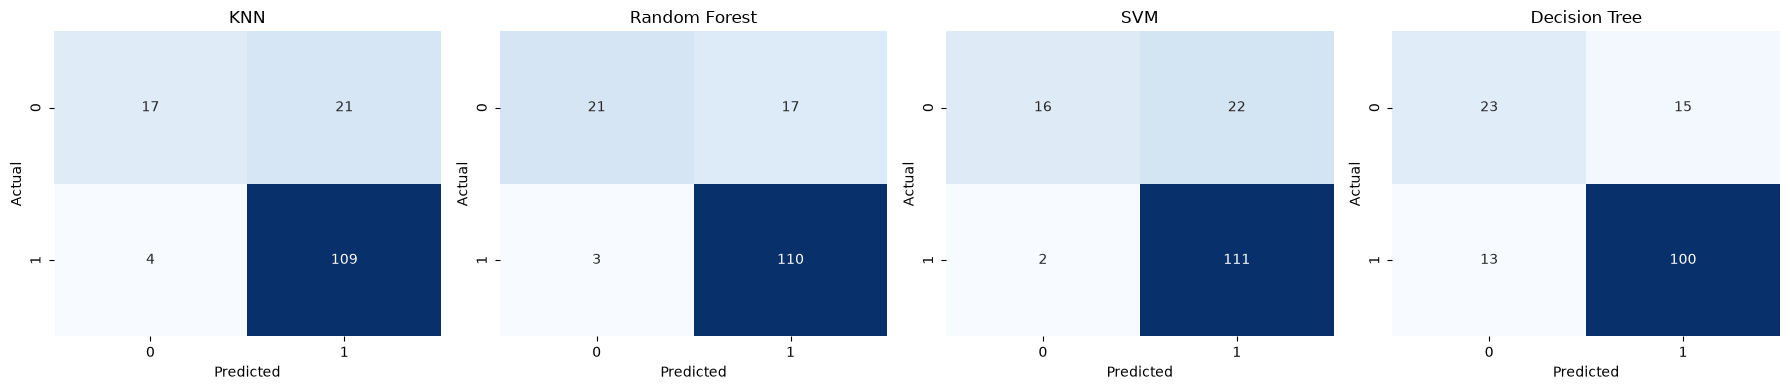

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [26]:
for name, pred in predictions.items():
    print(name)
    print(confusion_matrix(y_test, pred))
    print()

KNN
[[ 17  21]
 [  4 109]]

Random Forest
[[ 21  17]
 [  3 110]]

SVM
[[ 16  22]
 [  2 111]]

Decision Tree
[[ 23  15]
 [ 13 100]]



### Classification report for each model

In [27]:
for name, pred in predictions.items():
    print("=====", name, "=====")
    print(classification_report(y_test, pred, target_names=["Healthy (0)", "Parkinson's (1)"]))

===== KNN =====
                 precision    recall  f1-score   support

    Healthy (0)       0.81      0.45      0.58        38
Parkinson's (1)       0.84      0.96      0.90       113

       accuracy                           0.83       151
      macro avg       0.82      0.71      0.74       151
   weighted avg       0.83      0.83      0.82       151

===== Random Forest =====
                 precision    recall  f1-score   support

    Healthy (0)       0.88      0.55      0.68        38
Parkinson's (1)       0.87      0.97      0.92       113

       accuracy                           0.87       151
      macro avg       0.87      0.76      0.80       151
   weighted avg       0.87      0.87      0.86       151

===== SVM =====
                 precision    recall  f1-score   support

    Healthy (0)       0.89      0.42      0.57        38
Parkinson's (1)       0.83      0.98      0.90       113

       accuracy                           0.84       151
      macro avg       

### Summary

| Model | Accuracy | Healthy correctly found (recall 0) | Parkinson's correctly found (recall 1) |
|---|---|---|---|
| Random Forest | 86.75% | 21 of 38 (55%) | 110 of 113 (97%) |
| SVM | 84.11% | 16 of 38 (42%) | 111 of 113 (98%) |
| KNN | 83.44% | 17 of 38 (45%) | 109 of 113 (96%) |
| Decision Tree | 81.46% | 23 of 38 (61%) | 100 of 113 (88%) |

**What the results show:**
- **Random Forest is the best model**, with the highest accuracy (86.75%). It also has the highest F1-scores for both classes (0.68 for healthy and 0.92 for Parkinson's).
- **All models are very good at finding people who have Parkinson's.** Random Forest, SVM and KNN find 96–98% of them. This is the most important part for a medical tool, because missing a sick person is a bigger problem.
- **All models struggle with healthy people.** Many healthy people are wrongly predicted as having Parkinson's (false positives). For example, SVM only got 16 out of 38 healthy people right. The main reason is that the data has about 3 times more Parkinson's samples than healthy samples, so the models lean towards predicting Parkinson's.
- **The Decision Tree** has the lowest accuracy, but it is the best at finding healthy people (23 of 38). It also misses more Parkinson's patients (13) than the other models.
- **Accuracy alone can be misleading** here. A model that always said "Parkinson's" would already get about 75% accuracy (113 out of 151), so it is important to also look at the confusion matrix and the recall for the healthy class.

**Conclusion:** Random Forest is the best choice of the four models for this data. It could be useful as a support tool for doctors, but it should not be the only thing used to make a diagnosis because it still makes mistakes, mostly with healthy people. One more thing to keep in mind: each patient has 3 recordings, and with a random split the same patient can be in both the training and test data, so the real accuracy on brand new patients might be a little lower.


## Question 7: Save the test data predictions for all the models as a single csv file.

In [28]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "KNN": knn_pred,
    "Random Forest": rf_pred,
    "SVM": svm_pred,
    "Decision Tree": dt_pred,
})

results.to_csv(OUTPUT_FILE, index=False)
print("Predictions saved to", OUTPUT_FILE)
results.head()

Predictions saved to predictions/test_predictions.csv


,Actual,KNN,Random Forest,SVM,Decision Tree
0,1,0,1,1,1
1,1,1,1,1,1
2,0,0,0,0,0
3,1,1,1,1,1
4,0,0,0,0,0
